# Projet 5 — Détection d'attaques inconnues par Anomaly Detection

**Question centrale :** peut-on détecter des attaques inconnues sans disposer d'exemples de ces attaques pendant l'entraînement ?

**Dataset :** UNSW-NB15 (voir `data/README.md` pour le téléchargement).

Démarche détaillée : voir `roadmap.md`.

## 0. Configuration

In [27]:
import os
import sys
import time
import warnings
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
from scipy.stats import spearmanr

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, PrecisionRecallDisplay, RocCurveDisplay,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110


In [29]:
RANDOM_STATE = 42
DATA_DIR = os.environ.get("UNSW_DATA_DIR", "../data/raw")
TRAIN_FILE = "UNSW_NB15_training-set.csv"
TEST_FILE = "UNSW_NB15_testing-set.csv"
OUT_DIR = "../results"                    # tableaux et figures pour le rapport

FAST_MODE = os.environ.get("UNSW_FAST", "0") == "1"

VAL_SIZE = 0.2                         # part du train officiel gardée pour la validation
N_FIT = 2_000 if FAST_MODE else 20_000 # flux d'entraînement par détecteur
TARGET_FPR = 0.05                      # FPR visé sur les flux normaux de validation
FPR_LEVELS = [0.01, 0.02, 0.05, 0.10]  # niveaux pour l'analyse du compromis (H1, Q3)
CONTAMINATION_LEVELS = [0.0, 0.01, 0.02, 0.05, 0.10]
N_SEEDS = 1 if FAST_MODE else 3        # répétitions de l'expérience 2
UNKNOWN_FAMILIES = ["Reconnaissance", "Backdoor", "Shellcode", "Worms"]
CLIP_QUANTILE = 0.99
VOLUME_NORMAL_PAR_JOUR = 1_000_000     # hypothèse de volume pour traduire un FPR en alertes/jour (Q3)

os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(RANDOM_STATE)

def save_fig(fig, name):
    fig.savefig(os.path.join(OUT_DIR, f"{name}.png"), bbox_inches="tight")

def save_table(df, name):
    df.to_csv(os.path.join(OUT_DIR, f"{name}.csv"))

## 1. Problématique, compréhension du dataset et EDA ciblée

### Chargement des données

In [31]:
train_df = pd.read_csv(os.path.join(DATA_DIR, TRAIN_FILE))
test_df = pd.read_csv(os.path.join(DATA_DIR, TEST_FILE))
for df in (train_df, test_df):
    df["attack_cat"] = df["attack_cat"].astype(str).str.strip()

FEATURES = [c for c in train_df.columns if c not in ("id", "attack_cat", "label")]
CAT_COLS = ["proto", "service", "state"]

print("Valeurs manquantes :", int(train_df.isna().sum().sum()), "/", int(test_df.isna().sum().sum()))

Valeurs manquantes : 0 / 0


### EDA ciblée

In [25]:
print("Valeurs manquantes (train / test) :", train_df.isna().sum().sum(), "/", test_df.isna().sum().sum())
dup = train_df.drop(columns=["id"]).duplicated().sum()
print(f"Lignes dupliquées dans le train (hors id) : {dup} ({dup / len(train_df):.1%})")

label_dist = pd.DataFrame({
    "train": train_df["label"].value_counts(normalize=True),
    "test": test_df["label"].value_counts(normalize=True),
}).rename(index={0: "Normal", 1: "Attaque"})
label_dist.style.format("{:.1%}")

Valeurs manquantes (train / test) : 0 / 0
Lignes dupliquées dans le train (hors id) : 67601 (38.6%)


,train,test
label,,
Attaque,68.1%,55.1%
Normal,31.9%,44.9%


Part de flux normaux dupliqués dans le train : 7.3%


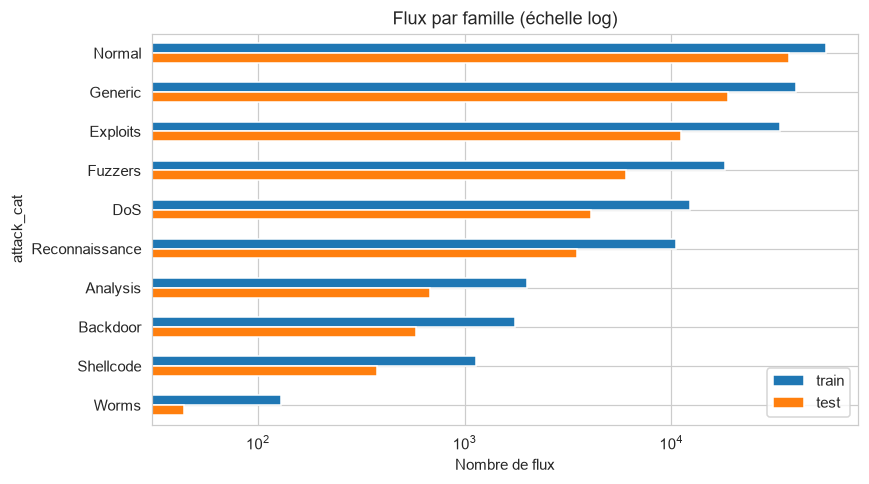

,train,test,inconnue (Exp. 3)
attack_cat,,,
Normal,56000,37000,False
Generic,40000,18871,False
Exploits,33393,11132,False
Fuzzers,18184,6062,False
DoS,12264,4089,False
Reconnaissance,10491,3496,True
Analysis,2000,677,False
Backdoor,1746,583,True
Shellcode,1133,378,True


In [32]:
fam = pd.DataFrame({
    "train": train_df["attack_cat"].value_counts(),
    "test": test_df["attack_cat"].value_counts(),
}).fillna(0).astype(int).sort_values("train", ascending=False)
fam["inconnue (Exp. 3)"] = fam.index.isin(UNKNOWN_FAMILIES)

dup_normal = train_df[train_df["label"] == 0].duplicated(subset=FEATURES).mean()
print(f"Part de flux normaux dupliqués dans le train : {dup_normal:.1%}")

fig, ax = plt.subplots(figsize=(8, 4.5))
fam[["train", "test"]].plot(kind="barh", logx=True, ax=ax)
ax.invert_yaxis()
ax.set_title("Flux par famille (échelle log)")
ax.set_xlabel("Nombre de flux")
plt.tight_layout(); save_fig(fig, "eda_familles"); plt.show()
fam